# EV TwinLab: synthetic consumers for EV concept testing (US)
*Draft report. Notebook, data and scripts are in this folder; see `README.md` to reproduce.*

**In one paragraph.** Carmakers need fast answers to marketing questions about new EV concepts: what price, which buyers, which features to stress. Surveys answer them but are slow and costly. We build a *synthetic panel*: realistic US personas generated with SDV from real survey microdata, an EV-demand benchmark that combines Pew's published shares with a choice model fitted on 5,898 real EV-vs-gasoline choices, and a reliability gate whose weights we calibrated on 280 real human-vs-AI comparisons. For an example EV ($45k, 300 miles, 30-minute fast charge), the panel puts the revenue-maximising price around \$40k. The strongest lever is not price but **charging access**: a fast charger in town is worth about \$12k to buyers. It suggests targeting under-30s, Democratic-leaning and environmentally minded buyers, with no need to limit campaigns to cities. Numbers rest on a 2019 stated-choice survey and published figures, and should be confirmed in a small human test.

## 1. Introduction: the problem

**Marketing problem.** A carmaker has an EV concept and must decide *price*, *target segments* and *message*. A consumer survey (n≈1,000) costs time and money for every concept variant.

**Idea.** Ask *synthetic respondents* (an LLM playing a persona) instead, and only run human research where the synthetic answer cannot be trusted.

**Two risks we address**
1. Personas must look like the real population, including how traits go together (age, income, politics, environmental values).
2. LLM answers can be wrong in systematic ways, so every result needs a reliability check before it is used.

**Pipeline (EV TwinLab)**

| Step | What | Built with |
|---|---|---|
| 1 Personas | Synthetic US consumers | SDV Gaussian copula trained on Twin-2K-500 microdata |
| 2 Respondent | Persona + EV concept → JSON answer | Prompts generated here; the LLM call is the next step (benchmark used as stand-in) |
| 3 Aggregation | Consideration share, WTP, segments | Benchmark: Pew 2025 level + choice model on the 2019 US EV survey |
| 4 Reliability gate | Accuracy, stability, diversity → HIGH/MEDIUM/LOW | Weights calibrated on Twin-2K-500 Mega-Study |

An interactive version of steps 1–4 is in `demo/ev-twinlab-us.html`.

In [1]:
import os; os.environ["TQDM_DISABLE"] = "1"   # silence SDV progress bars
import sys, json, importlib.util, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, INK, ORANGE, GREY = "#2b55c7", "#0f1a24", "#c2410c", "#9aa8b5"

def load(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod
sys.argv = ["notebook"]
evp = load("evp", "scripts/ev_personas_sdv.py")     # SDV persona pipeline + EV benchmark
DATA = "data"

## 2. Data

| Dataset | Content | Used for | Licence / status |
|---|---|---|---|
| **Twin-2K-500** (Toubia et al. 2025) | 2,058 US adults: demographics, personality and value scales | Training data for synthetic personas | CC-BY-4.0, in `data/` |
| **Twin-2K-500 Mega-Study** (Peng et al. 2026) | 19 studies, real answers vs. AI-twin answers | Calibrating the reliability-gate weights | Apache-2.0, results in `data/calibration_results.json` (raw file 214 MB, downloaded by script) |
| **Pew Research Center** 2025 | 33% of US adults would seriously consider an EV; Dem 48%, Rep 18% | EV benchmark targets | Published figures |
| **2019 EV purchase choice survey** (MacKenzie 2020) | 983 US car owners, 5,898 choices between an EV and a gasoline car | How price, range, charging and age move EV choice; held-out validation | CC0, in `data/ev_survey_2019/` |
| **US Census (ACS 2023)** | Age mix, median income | Re-weighting the age mix | Published / approximate |

The EV survey gives real trade-offs but not the real-world level of interest: in a hypothetical choice 55% picked the EV, while Pew finds 33% would seriously consider one. We therefore take the **level and party split from Pew** and **the trade-offs from the survey**. Anything that is neither published nor estimated is marked as an assumption in the scripts.

In [2]:
real = evp.build_real_table(DATA)
print(f"{len(real):,} real respondents, {real.shape[1]} variables")
real.head()

2,058 real respondents, 15 variables


,region,sex,age_band,education,race,party,income_band,ideology,household_size,employment,green_values,openness,risk_aversion,financial_literacy,spending_style
0,Midwest,Female,30-49,"Some college, no degree",Black,Independent,"$50,000-$75,000",Moderate,3,Part-time employment,4.000,3.5,0.306,3,7
1,Midwest,Female,50-64,"Some college, no degree",White,Democrat,"$30,000-$50,000",Very liberal,2,Retired,3.833,4.2,0.456,4,15
2,South,Male,65+,"Some college, no degree",White,Independent,"$30,000-$50,000",Moderate,2,Retired,3.167,4.5,-0.422,5,17
3,South,Male,50-64,College graduate/some postgrad,White,Democrat,"$75,000-$100,000",Very liberal,2,Full-time employment,5.000,5.0,0.100,6,9
4,South,Female,30-49,Associate's degree,White,Independent,"$75,000-$100,000",Moderate,More than 4,Home-maker,1.167,3.8,-0.128,4,9


## 3. Data exploration

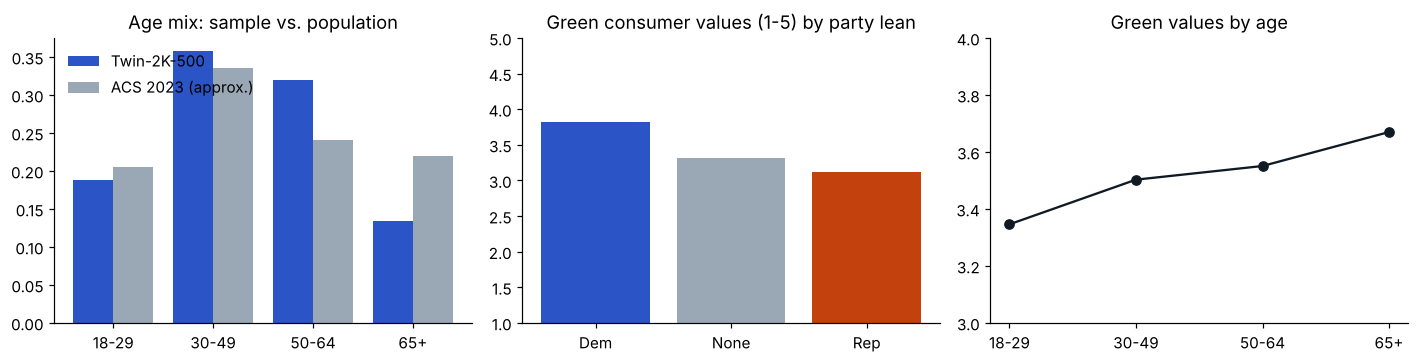

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
age = real.age_band.value_counts(normalize=True).reindex(evp.AGE)
acs = pd.Series(evp.ACS_AGE).reindex(evp.AGE)
x = np.arange(4)
ax[0].bar(x - .2, age, .4, color=BLUE, label="Twin-2K-500")
ax[0].bar(x + .2, acs, .4, color=GREY, label="ACS 2023 (approx.)")
ax[0].set_xticks(x, evp.AGE); ax[0].set_title("Age mix: sample vs. population"); ax[0].legend(frameon=False, loc="upper left")

lean = evp.lean(real)
g = real.assign(lean=lean).groupby("lean").green_values.mean().reindex(["Dem", "None", "Rep"])
ax[1].bar(g.index, g, color=[BLUE, GREY, ORANGE]); ax[1].set_ylim(1, 5)
ax[1].set_title("Green consumer values (1-5) by party lean")

ga = real.groupby("age_band").green_values.mean().reindex(evp.AGE)
ax[2].plot(evp.AGE, ga, marker="o", color=INK); ax[2].set_ylim(3, 4)
ax[2].set_title("Green values by age")
plt.tight_layout(); plt.show()

In [4]:
traits = ["green_values", "openness", "risk_aversion", "financial_literacy", "spending_style"]
num = real[traits].copy()
num["age (ordinal)"] = real.age_band.map({a: i for i, a in enumerate(evp.AGE)})
num["income (ordinal)"] = real.income_band.map({a: i for i, a in enumerate(evp.INC)})
num["liberal (ordinal)"] = real.ideology.map({a: i for i, a in enumerate(evp.IDEO)})
num.corr(method="spearman").round(2)

,green_values,openness,risk_aversion,financial_literacy,spending_style,age (ordinal),income (ordinal),liberal (ordinal)
green_values,1.00,0.34,0.05,0.01,-0.09,0.09,0.08,0.31
openness,0.34,1.00,-0.05,0.03,-0.05,0.06,-0.02,0.16
risk_aversion,0.05,-0.05,1.00,-0.04,-0.08,0.06,-0.07,-0.02
financial_literacy,0.01,0.03,-0.04,1.00,-0.12,0.11,0.12,0.01
spending_style,-0.09,-0.05,-0.08,-0.12,1.00,-0.07,0.06,0.00
age (ordinal),0.09,0.06,0.06,0.11,-0.07,1.00,-0.01,-0.12
income (ordinal),0.08,-0.02,-0.07,0.12,0.06,-0.01,1.00,-0.07
liberal (ordinal),0.31,0.16,-0.02,0.01,0.00,-0.12,-0.07,1.00


**What the exploration shows**
- The sample under-represents people aged 65+ (14% vs 22% in the population) and over-represents 50–64. We correct this by sampling personas to ACS age shares (`--match-acs-age`).
- **Green values differ by politics.** Democratic-leaning respondents score clearly higher than Republican-leaning ones. This matters because party lean is the strongest published driver of EV interest (Pew: 48% vs 18%).
- **Older people score higher on green values**, yet Pew finds they are less open to EVs. Green attitudes alone do not make an EV buyer, so messages for older buyers should address practical doubts (range, cost) rather than the environment.
- Traits are correlated (for example income with education, green values with liberal views). A persona generator that draws each variable on its own would break these links. That is the problem SDV solves.

### 3.2 Real EV choices (2019 survey)
Each of 983 car owners chose six times between an EV and a gasoline car. The EV's price (70–100% of their own car budget), range, fast-charging time and charger access varied between scenarios.

983 respondents, 5,898 choices, EV chosen 55% of the time


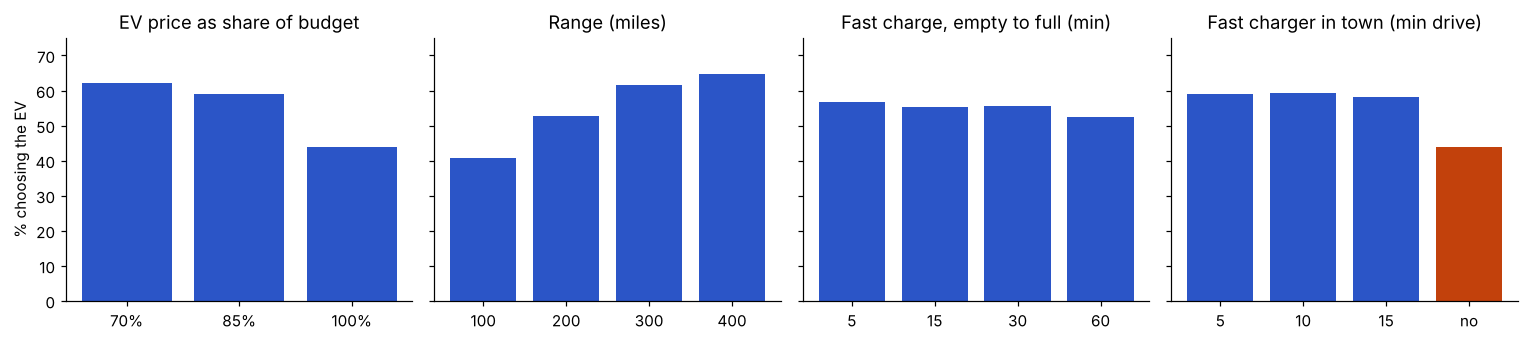

In [5]:
ev = pd.read_csv(f"{DATA}/ev_survey_2019/ev_choice_survey_2019.tab", sep="\t")
print(f"{ev.subject.nunique()} respondents, {len(ev):,} choices, EV chosen {ev.bichoice.mean():.0%} of the time")
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a_, (col, title, lab) in zip(ax, [("priceprop", "EV price as share of budget", lambda v: f"{v:.0%}"),
                                      ("range", "Range (miles)", str), ("fasttime", "Fast charge, empty to full (min)", str),
                                      ("town", "Fast charger in town (min drive)", str)]):
    g = ev.groupby(col).bichoice.mean()
    if col == "town": g = g.reindex(["5", "10", "15", "no"])
    a_.bar([lab(v) for v in g.index], g * 100, color=[ORANGE if str(v) == "no" else BLUE for v in g.index])
    a_.set_title(title); a_.set_ylim(0, 75)
ax[0].set_ylabel("% choosing the EV")
plt.tight_layout(); plt.show()

**What real buyers show**
- Price and range matter most in raw shares: the EV wins 62% of choices at 70% of budget and 44% at full budget; 41% at 100 miles and 65% at 400 miles.
- **No fast charger in town drops EV choice from about 59% to 44%.** Charger access is a bigger factor than charging speed (5 vs 60 minutes: 57% vs 52%).
- The sample is younger than the population (only 4% aged 65+) and shops at lower budgets (median \$20k, 54% buying used), so we use it for trade-offs, not levels.

## 4. Solution
### 4.1 Synthetic personas with SDV
We train SDV's Gaussian copula on 80% of the real respondents and compare its output with the 20% it never saw. The comparison also covers *independent draws* (the method in our first demo) and a real-vs-real sample, which is the best possible score.

In [6]:
md_ = evp.make_metadata(real)
rng = np.random.default_rng(7); hold = rng.random(len(real)) < 0.2
train, test = real[~hold].reset_index(drop=True), real[hold].reset_index(drop=True)
syn = evp.fit_synthesizer(train, md_, "gaussian_copula", 7)
quality = pd.DataFrame({
    "SDV synthetic": evp.quality(test, syn.sample(len(test))[evp.TABLE], md_),
    "Independent draws (old demo)": evp.quality(test, evp.independent_draws(train, len(test), 7), md_),
    "Real vs real (ceiling)": evp.quality(test, train.sample(len(test), random_state=7), md_)}).T
quality.round(2)

,overall,Column Shapes,Column Pair Trends
SDV synthetic,0.86,0.94,0.78
Independent draws (old demo),0.82,0.95,0.69
Real vs real (ceiling),0.92,0.95,0.89


In [7]:
big = syn.sample(5000)[evp.TABLE]
pd.DataFrame({"Real": evp.crosstabs(real), "SDV synthetic": evp.crosstabs(big),
              "Independent draws": evp.crosstabs(evp.independent_draws(train, 5000, 8))}).round(2)

,Real,SDV synthetic,Independent draws
"Democrat share, age 18-29",0.41,0.45,0.40
"Democrat share, age 65+",0.45,0.39,0.40
"Income $100k+, college degree",0.39,0.36,0.27
"Income $100k+, no degree",0.14,0.18,0.27
"Green values, Democrats",3.81,3.69,3.51
"Green values, Republicans",3.18,3.24,3.51
"Liberal or very liberal, age 18-29",0.48,0.48,0.45
"Liberal or very liberal, age 65+",0.45,0.40,0.42


SDV keeps most of the structure. Its column-pair score is close to the real-vs-real ceiling and clearly above independent draws. It also keeps the gaps that matter for EV marketing: income by education and green values by party. It is not perfect: older Democrats are under-represented, and very small groups (Hawaii/Alaska) are over-sampled.

### 4.2 Choice model on the real EV survey
A logit model of "chooses the EV" on the scenario and the person (`scripts/ev_survey_model.py`), with errors clustered by respondent. Price enters as a share of the person's budget, which fits better than dollars (AIC 7,507 vs 7,573): buyers judge price against what they planned to spend.

In [8]:
sv = json.load(open(f"{DATA}/ev_survey_model.json"))
coef = pd.DataFrame(sv["coefficients"]).set_index("term")[["coef", "ci90_low", "ci90_high", "p_value"]]
display(coef.round(3))
w = sv["wtp"]["at_budget_50k_reference_ev"]
labels = {"usd_per_mile_range": "per mile of range", "usd_per_minute_faster_charging": "per minute faster fast charging",
          "usd_per_minute_shorter_walk_home_charger": "per minute shorter walk to a home charger",
          "usd_fast_charger_in_town": "fast charger in town (vs none)", "usd_fast_chargers_on_highway": "fast chargers on the highway (vs none)"}
pd.DataFrame({labels[k]: {"WTP ($), buyer with $50k budget": w[k]["estimate"], "90% CI low": w[k]["ci90"][0], "90% CI high": w[k]["ci90"][1]}
              for k in labels}).T.round(0)

,coef,ci90_low,ci90_high,p_value
term,,,,
const,-0.591,-0.843,-0.338,0.000
price_gap_share,-2.763,-3.176,-2.350,0.000
range_100mi,0.366,0.318,0.414,0.000
fast_min,-0.003,-0.005,-0.001,0.019
home_walk_min,-0.024,-0.031,-0.017,0.000
work_walk_min,-0.019,-0.026,-0.012,0.000
no_town_fast,-0.669,-0.782,-0.556,0.000
no_highway_fast,-0.108,-0.199,-0.017,0.052
age_18_29,0.272,0.065,0.480,0.031


,"WTP ($), buyer with $50k budget",90% CI low,90% CI high
per mile of range,66.0,54.0,81.0
per minute faster fast charging,56.0,19.0,98.0
per minute shorter walk to a home charger,434.0,298.0,591.0
fast charger in town (vs none),12107.0,9623.0,14741.0
fast chargers on the highway (vs none),1950.0,434.0,3832.0


**Hold-out check on real people.** The model was refitted on 80% of respondents and predicted the other 196 people's choices. This is exactly step 4 of EV TwinLab ("compare with held-out humans"), now on real EV choices.

In [9]:
v = sv["validation"]
print(f"Accuracy {v['accuracy_model']:.0%} vs {v['accuracy_constant']:.0%} for always guessing the majority; "
      f"mean segment gap {v['mean_abs_segment_gap_points']} points -> accuracy score {100 - 5 * v['mean_abs_segment_gap_points']:.0f}/100")
pd.DataFrame(v["segments"]).set_index("segment")

Accuracy 62% vs 55% for always guessing the majority; mean segment gap 4.42 points -> accuracy score 78/100


,choices,actual,predicted,gap_points
segment,,,,
All,1176,0.556,0.528,-2.8
Age 18-29,198,0.646,0.594,-5.2
Age 30-49,690,0.554,0.528,-2.5
Age 50-64,258,0.488,0.474,-1.4
Age 65+,30,0.600,0.540,-6.0
Area rural,492,0.543,0.506,-3.7
Area suburban,378,0.545,0.543,-0.2
Area urban,306,0.592,0.544,-4.7
Income $100k+,228,0.610,0.535,-7.5


**Findings.** Real buyers value range at about \$66 per mile and a fast charger in town at about \$12,100 (buyer with a \$50k budget). Under-30s are clearly more likely to choose the EV. **Urban vs rural and income make no difference** once the offer is accounted for. Existing EV owners are much more likely to buy again. On held-out people the segment gap is 4.4 points, an accuracy score of 78: MEDIUM, just under HIGH. The model under-predicts EV owners and used-car buyers.

### 4.3 EV demand benchmark for the personas
Each persona gets a probability of seriously considering the EV. At a reference EV (\$50k, 270 mi, 30 min) the personas reproduce Pew's shares (Dem-leaning 48%, Rep-leaning 18%). Price, range, fast charging and age then move demand with the survey's coefficients, and green values add individual variation. In production, step 2 replaces this benchmark with real LLM answers to the prompts in `prompts.jsonl`, and the benchmark becomes the yardstick.

In [10]:
personas = evp.sample(evp.fit_synthesizer(real, md_, "gaussian_copula", 7), 5000, match_acs_age=True)
bench = evp.EVBenchmark(real, 7)
print("Fit at reference EV:", {k: v for k, v in bench.fit_check.items() if k.startswith(("lean=D", "lean=R", "overall"))})
CONCEPT = dict(price=45000, range=300, charge=30)
P = bench.apply(personas, CONCEPT, 11)
P[["age_band", "party", "income_band", "green_values", "ev_attitude_1to5", "max_price_usd", "p_consider_benchmark"]].head()

Fit at reference EV: {'lean=Dem': 0.48, 'lean=Rep': 0.18, 'overall': 0.36}


,age_band,party,income_band,green_values,ev_attitude_1to5,max_price_usd,p_consider_benchmark
0,18-29,Republican,"$50,000-$75,000",2.742,2,27800.0,0.259
1,50-64,Democrat,"$50,000-$75,000",3.369,5,62300.0,0.741
2,65+,Republican,"$30,000-$50,000",3.940,3,42900.0,0.462
3,65+,Independent,"$50,000-$75,000",2.997,1,11100.0,0.112
4,18-29,Democrat,"$50,000-$75,000",3.393,4,50300.0,0.581


### 4.4 Reliability gate, calibrated on real data
Synthetic answers are only useful if we know when to trust them. Our first demo used made-up weights (50% accuracy, 30% stability, 20% diversity). We calibrated them on the Twin-2K-500 Mega-Study: 280 cases where AI twins and the real people answered the same questions. Each case is scored on half the people and questions, and the true error is measured on the rest (`scripts/calibrate_weights.py`).

In [11]:
cal = json.load(open(f"{DATA}/calibration_results.json"))
jobs = pd.DataFrame({j: {**v["weights"], "out-of-sample rank corr.": v["cv_spearman"]["fitted"]["mean_within_study_spearman"]}
                     for j, v in cal["jobs"].items()}).T
display(jobs.round(2))
pd.DataFrame(cal["calibration_table"]).rename(columns={"score": "accuracy score"})

,accuracy,stability,diversity,out-of-sample rank corr.
level_estimates,1.00,0.00,0.00,0.38
segment_ranking,0.00,0.54,0.46,0.13
concept_ranking,0.42,0.58,0.00,0.13


,accuracy score,n,share_error_le_5,share_error_le_10,median_error
0,0-40,95,0.17,0.31,15.8
1,40-50,35,0.06,0.40,11.1
2,50-60,49,0.02,0.63,9.0
3,60-70,47,0.09,0.66,8.7
4,70-80,18,0.39,0.72,5.6
5,80-100,36,0.64,0.78,3.7


**Result.** To estimate *levels* (shares, WTP), accuracy alone is the best score. It ranks AI set-ups better than the proposed 50/30/20 (0.40 vs 0.33). Stability and diversity added nothing. With accuracy ≥ 80 the median error on a new question was 3.7 points, and below 60 it was 9–16 points, so the 80/60 gate cut-offs hold. **No score predicts segment or concept *rankings* well.** That is a warning for the marketing uses below.

## 5. Marketing component
All results below are for the example EV (\$45k, 300 miles, 30 minutes) on 5,000 SDV personas, using the benchmark from 4.3. They show how the tool supports marketing decisions; confirm the key numbers in a small human test.

### 5.1 Pricing: demand curve and revenue

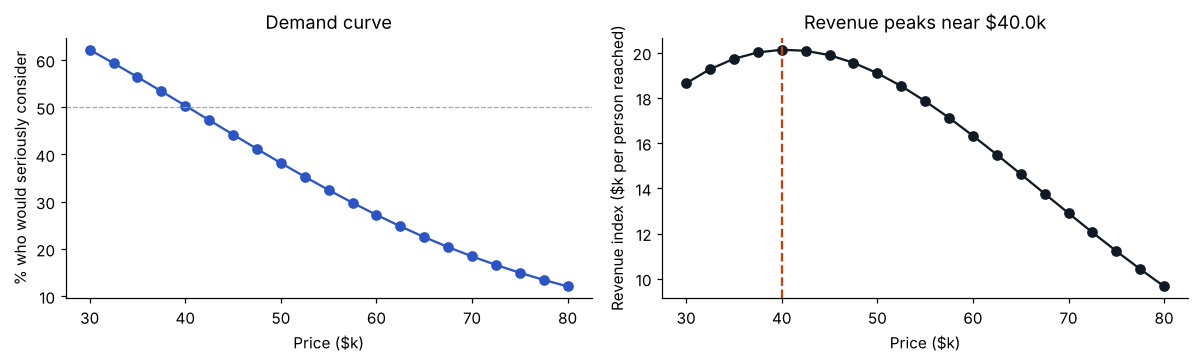

Median willingness to pay: $40,267.  Revenue-maximising price: $40,000 (revenue, not profit: no cost data).


In [12]:
prices = np.arange(30000, 80001, 2500)
share = np.array([bench.apply(personas, dict(CONCEPT, price=int(p)), 11).p_consider_benchmark.mean() for p in prices])
rev = share * prices / 1000
best = prices[rev.argmax()]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(prices / 1000, share * 100, marker="o", color=BLUE); ax[0].axhline(50, color=GREY, lw=.8, ls="--")
ax[0].set_xlabel("Price ($k)"); ax[0].set_ylabel("% who would seriously consider"); ax[0].set_title("Demand curve")
ax[1].plot(prices / 1000, rev, marker="o", color=INK); ax[1].axvline(best / 1000, color=ORANGE, ls="--")
ax[1].set_xlabel("Price ($k)"); ax[1].set_ylabel("Revenue index ($k per person reached)"); ax[1].set_title(f"Revenue peaks near ${best/1000:.1f}k")
plt.tight_layout(); plt.show()
wtp = np.interp(0.5, share[::-1], prices[::-1])
print(f"Median willingness to pay: ${wtp:,.0f}.  Revenue-maximising price: ${best:,.0f} (revenue, not profit: no cost data).")

### 5.2 Targeting: who to aim at

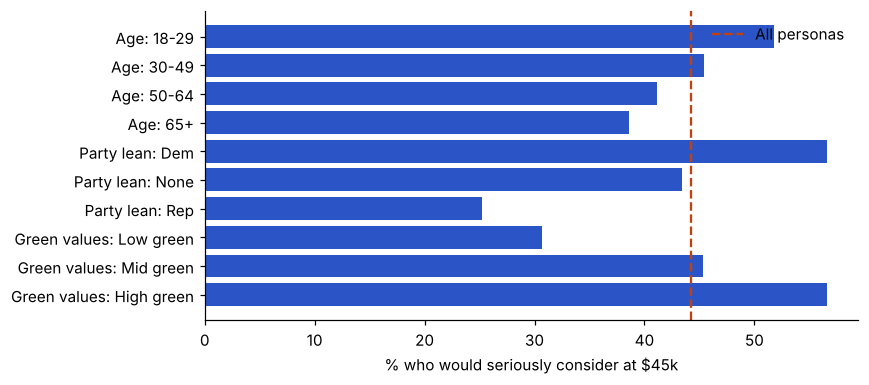

,dimension,segment,population_share,consider,share_of_demand
0,Age,18-29,0.20,0.52,0.24
1,Age,30-49,0.34,0.45,0.34
2,Age,50-64,0.24,0.41,0.22
3,Age,65+,0.22,0.39,0.19
4,Party lean,Dem,0.54,0.57,0.69
5,Party lean,None,0.12,0.43,0.11
6,Party lean,Rep,0.35,0.25,0.20
7,Green values,Low green,0.33,0.31,0.23
8,Green values,Mid green,0.33,0.45,0.34
9,Green values,High green,0.33,0.57,0.43


In [13]:
P["green_level"] = pd.qcut(P.green_values, 3, labels=["Low green", "Mid green", "High green"])
rows = []
for col, label in [("age_band", "Age"), ("party_lean", "Party lean"), ("green_level", "Green values")]:
    for k, g in P.groupby(col, observed=True):
        rows.append(dict(dimension=label, segment=str(k), population_share=len(g) / len(P),
                         consider=g.p_consider_benchmark.mean(),
                         share_of_demand=g.p_consider_benchmark.sum() / P.p_consider_benchmark.sum()))
seg = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(seg.dimension + ": " + seg.segment, seg.consider * 100, color=BLUE)
ax.axvline(P.p_consider_benchmark.mean() * 100, color=ORANGE, ls="--", label="All personas")
ax.invert_yaxis(); ax.set_xlabel("% who would seriously consider at $45k"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
seg.round(2)

### 5.3 Product levers: what moves demand most

In [14]:
base = P.p_consider_benchmark.mean()
levers = {"Price -$5,000": dict(CONCEPT, price=40000), "Range +50 miles": dict(CONCEPT, range=350),
          "Fast charge -10 minutes": dict(CONCEPT, charge=20)}
out = {k: (bench.apply(personas, c, 11).p_consider_benchmark.mean() - base) * 100 for k, c in levers.items()}
# charging access, from the survey coefficients (logit shift on each persona)
coefs = coef["coef"]
lp = np.log(P.p_consider_benchmark / (1 - P.p_consider_benchmark))
for k, du in {"Fast charger in town (vs none)": -coefs["no_town_fast"],
              "Home charger 10 minutes closer": -10 * coefs["home_walk_min"]}.items():
    out[k] = (1 / (1 + np.exp(-(lp + du)))).mean() * 100 - base * 100
pd.Series(out, name="change in consideration (points)").sort_values(ascending=False).round(1).to_frame()

,change in consideration (points)
Fast charger in town (vs none),12.8
"Price -$5,000",6.1
Home charger 10 minutes closer,4.6
Range +50 miles,3.5
Fast charge -10 minutes,0.6


### 5.4 Marketing recommendations (draft)

| Decision | Recommendation from the synthetic panel | Confidence |
|---|---|---|
| **Price** | Around \$40k. Revenue is nearly flat from \$37.5k to \$47.5k, so price is not the main lever: a \$5k cut adds only about 6 points. | MEDIUM: survey trade-offs, held-out accuracy score 78 |
| **Charging bundle (biggest lever)** | Guarantee charging access: partner with a fast-charging network and offer home-charger installation. A fast charger in town is worth about \$12k to buyers, about twice the effect of a \$5k price cut (+13 vs +6 points). | MEDIUM-HIGH: strongest, most precise effect in the survey |
| **Target segments** | Under-30s first, then Democratic-leaning and high-green buyers. Do not limit campaigns to cities: urban and rural buyers react the same. Existing EV owners are a loyal base for conquest and upgrade offers. | MEDIUM for age and EV owners (survey); LOW-MEDIUM for rankings |
| **Message: green segment** | Environmental impact, clean energy, a modern brand. | Hypothesis |
| **Message: low-green / Republican-leaning** | Running-cost savings, performance, independence from fuel prices. Avoid climate framing. | Hypothesis, follows Pew's partisan gap |
| **Product** | Stress range over charging speed: buyers value range at about \$66 per mile; ten minutes faster charging adds under 1 point. | MEDIUM: survey estimate with tight interval |
| **Channel** | Digital channels for under-30s; dealer and finance offers for buyers on tight budgets, who judge price against their budget. | Hypothesis |

## 6. Summary
- **Problem:** EV marketing decisions (price, target, message) need consumer evidence faster than surveys can deliver.
- **Solution:** a synthetic panel with three parts. SDV personas learned from 2,058 real US respondents keep how traits go together (pair-trend score 0.78 vs 0.69 for independent draws). An EV benchmark combines Pew's published level with a choice model on 5,898 real EV choices (held-out accuracy score 78). A reliability gate is calibrated on 280 real human-vs-AI comparisons.
- **Key insights:** the gate should use accuracy only (accuracy ≥ 80 meant a median error of about 4 points). For the example EV: price around \$40k; charging access is the strongest lever (a fast charger in town is worth about \$12k); target under-30s and green-minded buyers, in cities and rural areas alike; lead with range, not charging speed.
- **Limits:** the EV survey is from 2019, uses hypothetical choices and has few buyers over 65 or above \$50k. The step-2 LLM call is not run yet. Calibration data are psychology and consumer studies, not car choice. The persona training sample leans Democratic.
- **Next steps:** (1) run step 2 with 2–3 LLMs on `prompts.jsonl` and score them against the held-out survey respondents; (2) a small, current human EV pilot (about 300 people, 5 concepts) to confirm price and charging effects; (3) correct the persona party mix to Pew.

### Reproducibility
```bash
pip install -r requirements.txt            # SDV: install from the provided SDV-main.zip
python scripts/ev_survey_model.py          # choice model on the 2019 EV survey -> data/ev_survey_model.json
python scripts/ev_personas_sdv.py --data-dir data --n 1000 --match-acs-age --out outputs
python scripts/calibrate_weights.py results.zip data/w13_label.csv data/calibration_results.json   # results.zip from Hugging Face
jupyter nbconvert --to notebook --execute EV_TwinLab_report.ipynb
```